# 1. Libraries

In [2]:
# Import pandas
import pandas as pd

# Import numpy
import numpy as np

# Import timeit to measure running time
import timeit

# Import seaborn for plotting
import seaborn as sns

# Set style of seaborn library 
sns.set_style("darkgrid")

# Import matplotlib for plotting
from matplotlib import pyplot as plt

# 2. Modules

In [3]:
from data_module import *

from evaluation_module import *

from linear_module import *

from non_linear_module import *

# 3. Raw Data

### 3.1 Specification

In [4]:
# Specify time period 
Start = "01/31/1986" 
End = "12/31/2018" 

# Define feature variables 
Features_v = ["Momentum_12_1M", "BookToPrice", "Mcap_BMI_USD", "ROA", "Reversal_1M", "dShsOut_24m",
              "Beta_36M", "dAssets12M", "DividendYield", "DtD_Book", "EarningsToPrice", "EP_FWD_FY1",
              "LiabChangeToAssets", "LiabToAssets", "NetPayoutYield", "ResMom_12_1M_index",
              "Reversal_60_12M", "ROE", "SalesToPrice", "SeaRet5y", "Volatility_36M"]

# Define return variable 
Return_v = "TotalReturnUSD"

# Define market size variable 
Size_v = "Mcap_BMI_USD"

# Specify method (rolling or expanding)
Method = "rolling"  

# Specify after how many month the model is refitted 
Refit = 12

# Specify years of rolling window/min years of expanding method
Years = 10

# Specify number of portfolios for backtesting
N = 10

# Specify validation method: walk-forward (wf) or blocking walk-forward (bwf)
Validation = "wf"

# Specify the years used for validation.
Val_size=1

# Specify number of splits for validation
N_splits=3

### 3.2 Import 

In [5]:
# Import data 
Features, Return, Response, Size = import_data(Features=Features_v, 
                                               Return=Return_v, 
                                               Size=Size_v, 
                                               Start=Start, 
                                               End=End)

# 4. Data Processing

### 4.1 Take log of Size feature

In [6]:
# Take log of size variable
Features.loc[:,"Mcap_BMI_USD"] = Features.loc[:,"Mcap_BMI_USD"].apply(np.log)

# Rename column
Features.rename(columns={"Mcap_BMI_USD":"log_Mcap_BMI_USD"}, inplace=True)

### 4.2 Concat Data and drop NAs

In [7]:
# Concat variables
Data = pd.concat([Features, Return, Response, Size], axis=1)

# Drop inf and NAs
Data = Data.replace([np.inf, -np.inf], np.nan).dropna(how="any")

### 4.3 Winsorize features

In [8]:
# Winsorize features 
Data = winsorize_panel(Panel_Data=Data, 
                       Features=Features.columns, 
                       Upper=0.01, 
                       Lower=0.01)

### 4.4 Show Statistics

In [9]:
# Compute statistics
Data_stats = stats_panel(Panel_Data=Data, 
                         Variables=list(Features.columns)+[Return_v])

# Show statistics
Data_stats

,Avg,Std,N
Momentum_12_1M,0.12,0.39,4177
BookToPrice,0.64,0.48,4177
log_Mcap_BMI_USD,6.64,1.49,4177
ROA,0.03,0.09,4177
Reversal_1M,0.01,0.10,4177
dShsOut_24m,0.03,0.09,4177
Beta_36M,1.05,0.71,4177
dAssets12M,1.13,0.29,4177
DividendYield,1.92,2.15,4177
DtD_Book,4.68,2.03,4177


### 4.5 Demean Return

In [10]:
# Demean return variable
Data = demean(Data=Data, Variable=['TotalReturnUSD t+1', 'TotalReturnUSD'])

# 5 Tree based methods

### 5.1 Specification

In [11]:
# Define features for penalized linear Model
TB_raw_Features = ["Momentum_12_1M", "BookToPrice", "log_Mcap_BMI_USD", "ROA", "Reversal_1M", "dShsOut_24m",
                   "Beta_36M", "dAssets12M", "DividendYield", "DtD_Book", "EarningsToPrice", "EP_FWD_FY1",
                   "LiabChangeToAssets", "LiabToAssets", "NetPayoutYield", "ResMom_12_1M_index",
                   "Reversal_60_12M", "ROE", "SalesToPrice", "SeaRet5y", "Volatility_36M"]

### 5.2 Data

In [12]:
# Gather data
TB_raw_Data = gather_data(Data=Data, 
                          Features=TB_raw_Features)

# Compute statistics
TB_raw_Data_stats = stats_panel(Panel_Data=TB_raw_Data, 
                                Variables=TB_raw_Features+[Return_v])

# Show statistics
TB_raw_Data_stats

,Avg,Std,N
Momentum_12_1M,0.12,0.39,4177
BookToPrice,0.64,0.48,4177
log_Mcap_BMI_USD,6.64,1.49,4177
ROA,0.03,0.09,4177
Reversal_1M,0.01,0.10,4177
dShsOut_24m,0.03,0.09,4177
Beta_36M,1.05,0.71,4177
dAssets12M,1.13,0.29,4177
DividendYield,1.92,2.15,4177
DtD_Book,4.68,2.03,4177


# Random Forest

### 5.3 Hyperparameter

Importtant Hyperparameters: 
1. Number of trees (n_estimators)
2. Number of features to consider at each split (max_features)
3. Deepth of the tree (min_samples_leaf, max_depth, min_samples_split, min_weight_fraction_leaf, max_leaf_nodes, min_impurity_decrease)

### 5.4 Fit + Predictions

In [12]:
# Run random forests and make precitions 
RF_raw_Pre, \
RF_raw_Pre_stats, \
RF_Fi, \
RF_Fi_avg, \
Years = rf(Data=TB_raw_Data,             # data
           Features=TB_raw_Features,     # feature variables 
           Response=Response.columns,    # response variable 
           Method=Method,                # rolling or expanding method
           Years=Years,                  # years of rolling window/min years of expanding
           Refit=Refit,                  # months after which the model is refitted
           Stats=True,                   # wheter to compute summary statistics
           Validation=Validation,        # walk-forward (wf) or blocking walk-forward (bwf)
           Val_size=Val_size,            # validation size
           N_splits=N_splits,            # number of splits  
           bootstrap=True,               # whether bootstrap samples are used when building trees
           Verbose=True,                 # whether to print status
           param_grid=[{"n_estimators":[100],                # number of trees in the forest
                        "max_features": ["sqrt"],            # number of features to consider for the best split
                        "min_samples_leaf":[.002, .004, .006, .008]    # minimum number of samples required to be at a leaf node 
                      # "min_weight_fraction_leaf":[],       # minimum weighted fraction of the sum total of weights
                      # "max_depth":[],                      # maximum depth of the tree.
                      # "min_samples_split":[],              # minimum number of samples to split an internal node
                      # "max_leaf_nodes":[],                 # grow trees with max_leaf_nodes in best-first fashion
                      # "min_impurity_decrease":[],          # split if decrease of the impurity greater this value
                      }]) 

# Show stats for predictions
RF_raw_Pre_stats

1. Iteration completed
2. Iteration completed
3. Iteration completed
4. Iteration completed
5. Iteration completed
6. Iteration completed
7. Iteration completed
8. Iteration completed
9. Iteration completed
10. Iteration completed
11. Iteration completed
12. Iteration completed
13. Iteration completed
14. Iteration completed
15. Iteration completed
16. Iteration completed
17. Iteration completed
18. Iteration completed
19. Iteration completed
20. Iteration completed
Running time = 229.60 mins


,Prediction
Avg,0.05
Std,0.60
p10,-0.70
p90,0.75


### Feature importance average

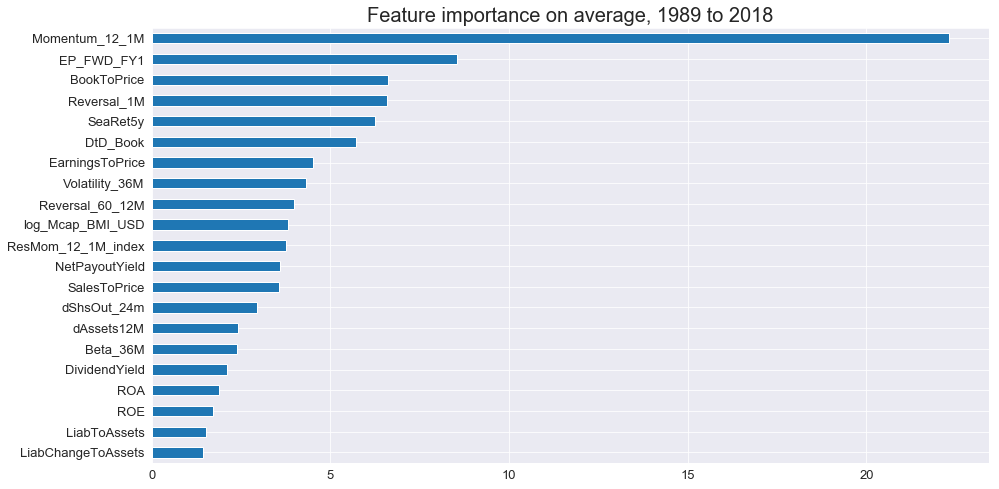

In [13]:
RF_Fi_avg.plot.barh(
figsize=[15,8],
fontsize=13,                                                              
title ="Feature importance on average, %.0f to %.0f" 
% (TB_raw_Data.index[0][0].year, TB_raw_Data.index[-1][0].year)).title.set_size(20);

### Feature importance over time

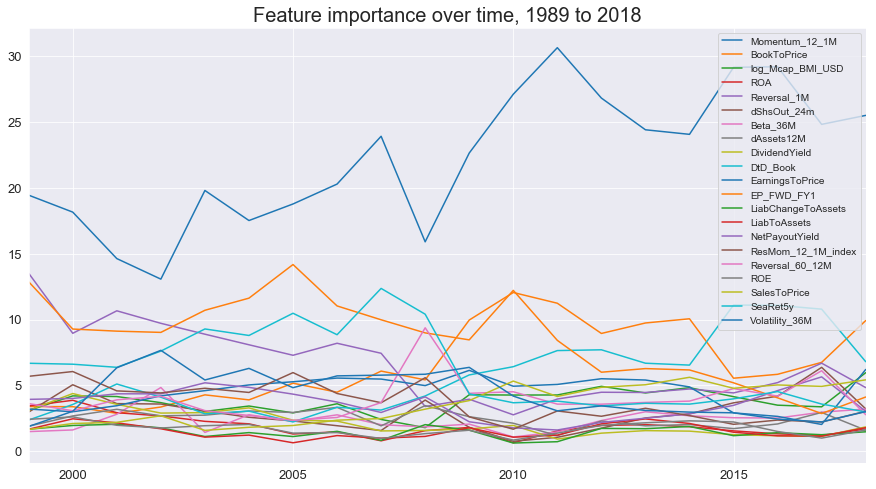

In [14]:
RF_Fi.plot.line(
figsize=[15,8],
fontsize=13,                                                              
title ="Feature importance over time, %.0f to %.0f" 
% (TB_raw_Data.index[0][0].year, TB_raw_Data.index[-1][0].year)).title.set_size(20);

### 5.5 Evaluation

In [15]:
# Create evaluation table
RF_raw_Eval_Data = eval_data(Data=TB_raw_Data, 
                             Predictions=RF_raw_Pre, 
                             Return=Return_v, 
                             Size=Size_v)

# Create Portfolios
RF_raw_Eval_Port, RF_raw_Eval_Port_cRet = portfolios(Eval_Data=RF_raw_Eval_Data, N=N)

# Regress return on prediction and compute statistics
RF_raw_Eval_Reg = linear_eval_reg(Eval_Data=RF_raw_Eval_Data)

# Show statistic
RF_raw_Eval_Reg

,Prediction
Slope,0.88
S.E.,0.11
t-stat,8.10


### cum. Outperformance 

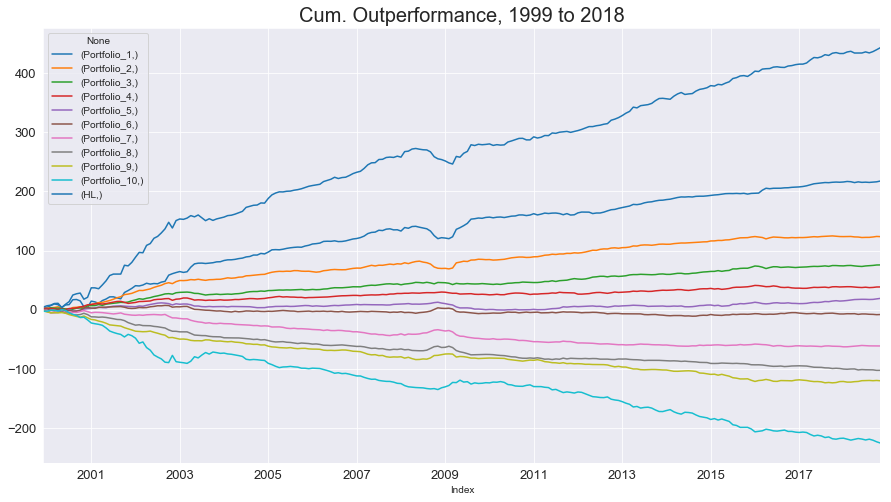

In [16]:
RF_raw_Eval_Port_cRet[RF_raw_Eval_Port_cRet.columns].plot.line(
figsize=[15,8],
fontsize=13,                                                              
title ="Cum. Outperformance, %.0f to %.0f" 
% (RF_raw_Eval_Data.index[0][0].year, RF_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### Returns vs Predictions

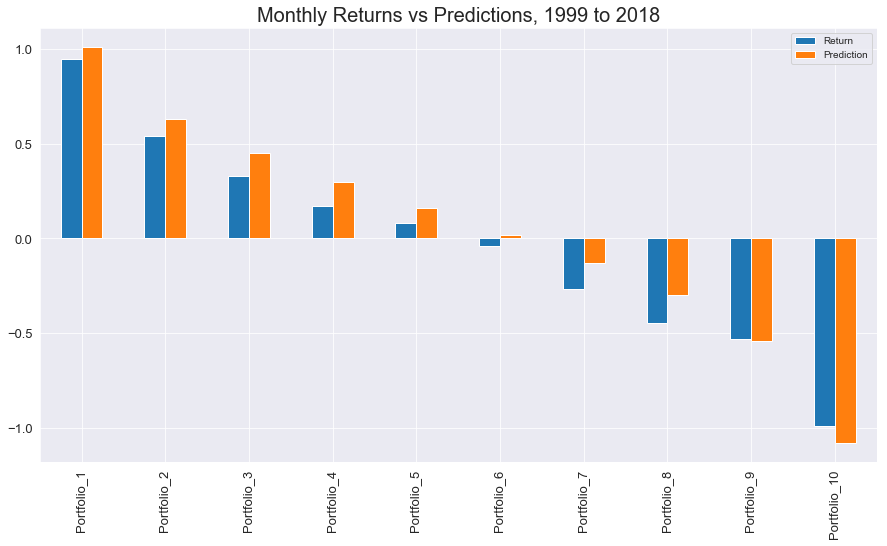

In [17]:
RF_raw_Eval_Port.loc[:,["Return","Prediction"]].iloc[:-1].plot.bar(
figsize=[15,8],
fontsize=13,
title ="Monthly Returns vs Predictions, %.0f to %.0f" 
% (RF_raw_Eval_Data.index[0][0].year, RF_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### Standard deviations

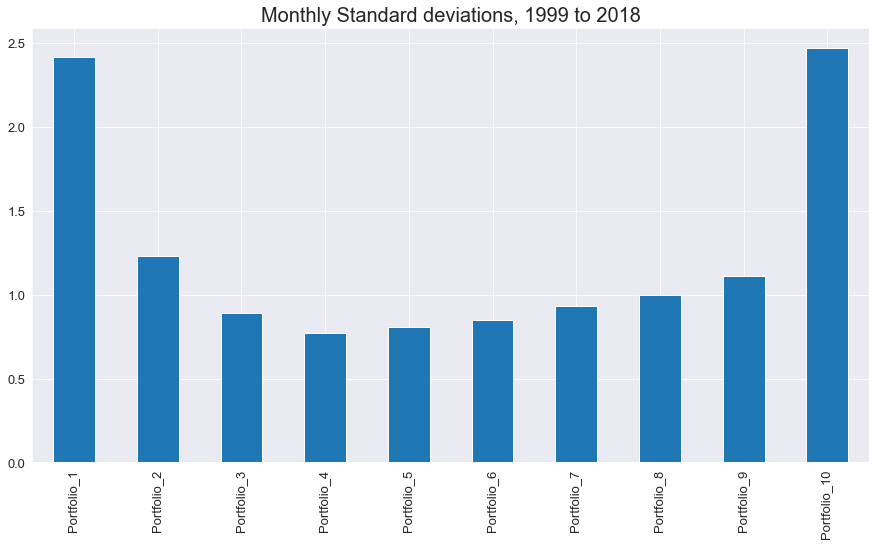

In [18]:
RF_raw_Eval_Port.loc[:,"Std"].iloc[:-1].plot.bar(
figsize=[15,8], 
fontsize=13,
title ="Monthly Standard deviations, %.0f to %.0f" 
% (RF_raw_Eval_Data.index[0][0].year, RF_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### Information Ratios

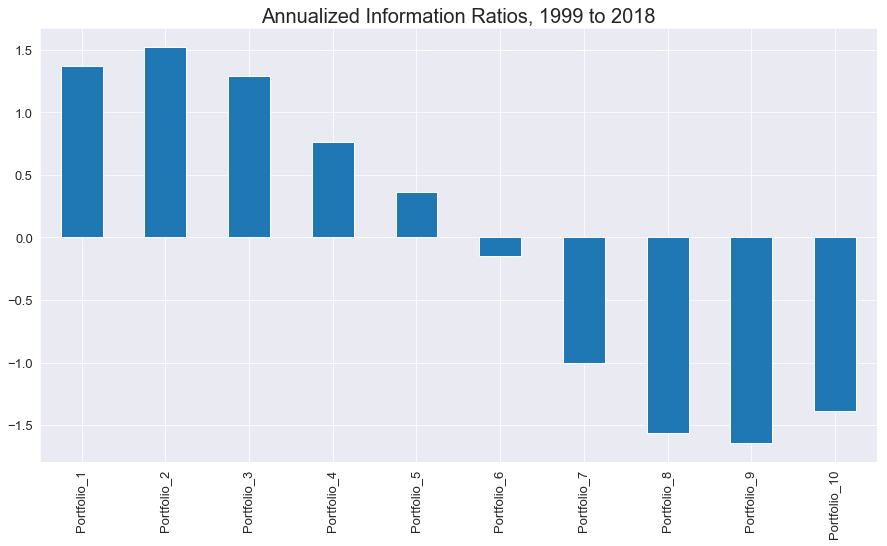

In [19]:
RF_raw_Eval_Port.loc[:,"IR"].iloc[:-1].plot.bar(
figsize=[15,8],
fontsize=13,
title ="Annualized Information Ratios, %.0f to %.0f" 
% (RF_raw_Eval_Data.index[0][0].year, RF_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### 5.6 Store Model

In [20]:
# Store dataframes 
RF_raw_Eval_Port.to_pickle("RF_raw_Eval_Port")
RF_raw_Eval_Reg.to_pickle("RF_raw_Eval_Reg")
RF_raw_Eval_Port_cRet.to_pickle("RF_raw_Eval_Port_cRet")

# Boosted Regression Trees

### 5.3 Hyperparameter

Importtant Hyperparameters: 
1. Number of trees (n_estimators)
2. Shrinkage parameter (learning_rate)
3. Deepth of the tree (min_samples_leaf, max_depth, min_samples_split, min_weight_fraction_leaf, max_leaf_nodes, min_impurity_decrease)

### 5.4 Fit + Predictions

In [13]:
# Run boosted regressions and make precitions 
BRT_raw_Pre, \
BRT_raw_Pre_stats, \
BRT_Fi, \
BRT_Fi_avg, \
Years = brt(Data=TB_raw_Data,            # data
           Features=TB_raw_Features,     # feature variables 
           Response=Response.columns,    # response variable 
           Method=Method,                # rolling or expanding method
           Years=Years,                  # years of rolling window/min years of expanding
           Refit=Refit,                  # months after which the model is refitted
           Stats=True,                   # wheter to compute summary statistics
           Validation=Validation,        # walk-forward (wf) or blocking walk-forward (bwf)
           Val_size=Val_size,            # validation size
           N_splits=N_splits,            # number of splits  
           Verbose=True,                 # whether to print status
           param_grid=[{"n_estimators":[100],                 # number of trees in the forest
                        "max_features": ["auto"],             # number of features to consider for the best split
                        "learning_rate":[.05, .1, .15],   # learning rate shrinks the contribution of each tree
                        "max_depth":[4],                      # maximum depth of the tree.
                      # "min_samples_leaf":[]                 # minimum number of samples required to be at a leaf node
                      # "min_weight_fraction_leaf":[],        # minimum weighted fraction of the sum total of weights
                      # "min_samples_split":[],               # minimum number of samples to split an internal node
                      # "max_leaf_nodes":[],                  # grow trees with max_leaf_nodes in best-first fashion
                      # "min_impurity_decrease":[],           # split if decrease of the impurity greater this value.
                      }]) 

# Show stats for predictions
BRT_raw_Pre_stats

1. Iteration completed
2. Iteration completed
3. Iteration completed
4. Iteration completed
5. Iteration completed
6. Iteration completed
7. Iteration completed
8. Iteration completed
9. Iteration completed
10. Iteration completed
11. Iteration completed
12. Iteration completed
13. Iteration completed
14. Iteration completed
15. Iteration completed
16. Iteration completed
17. Iteration completed
18. Iteration completed
19. Iteration completed
20. Iteration completed
Running time = 553.62 mins


,Prediction
Avg,0.09
Std,1.21
p10,-0.67
p90,0.69


### Feature importance on average

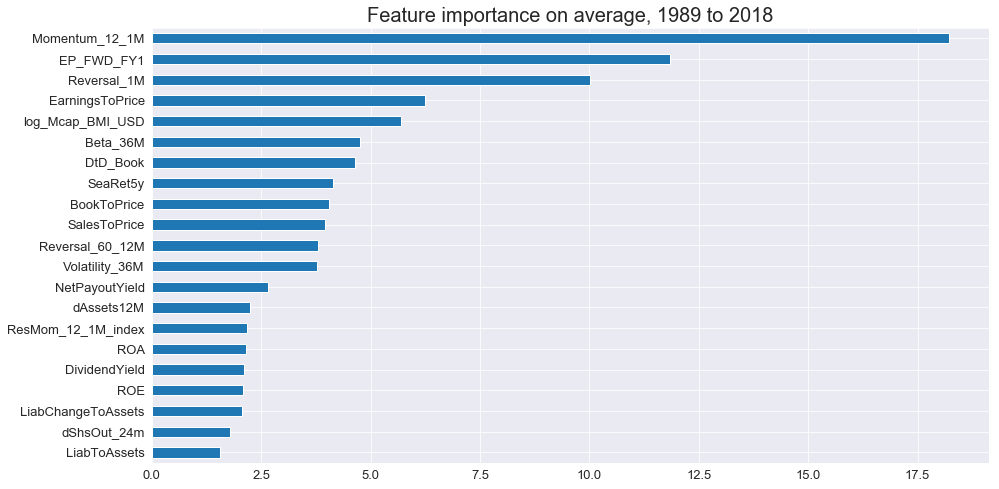

In [14]:
BRT_Fi_avg.plot.barh(
figsize=[15,8],
fontsize=13,                                                              
title ="Feature importance on average, %.0f to %.0f" 
% (TB_raw_Data.index[0][0].year, TB_raw_Data.index[-1][0].year)).title.set_size(20);

### Feature importance over time

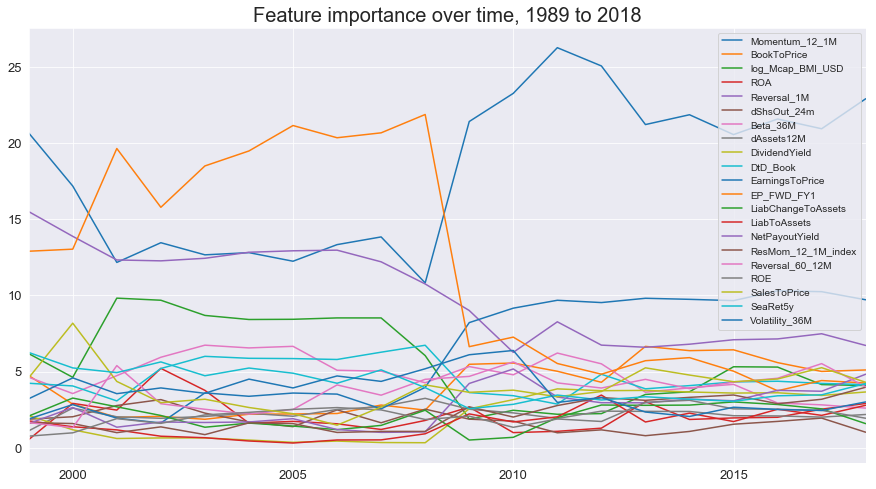

In [15]:
BRT_Fi.plot.line(
figsize=[15,8],
fontsize=13,                                                              
title ="Feature importance over time, %.0f to %.0f" 
% (TB_raw_Data.index[0][0].year, TB_raw_Data.index[-1][0].year)).title.set_size(20);

### 5.5 Evaluation

In [16]:
# Create evaluation table
BRT_raw_Eval_Data = eval_data(Data=TB_raw_Data, 
                             Predictions=BRT_raw_Pre, 
                             Return=Return_v, 
                             Size=Size_v)

# Create Portfolios
BRT_raw_Eval_Port, BRT_raw_Eval_Port_cRet = portfolios(Eval_Data=BRT_raw_Eval_Data, N=N)

# Regress return on prediction and compute statistics
BRT_raw_Eval_Reg = linear_eval_reg(Eval_Data=BRT_raw_Eval_Data)

# Show statistic
BRT_raw_Eval_Reg

,Prediction
Slope,0.69
S.E.,0.10
t-stat,7.19


### cum. Outperformance

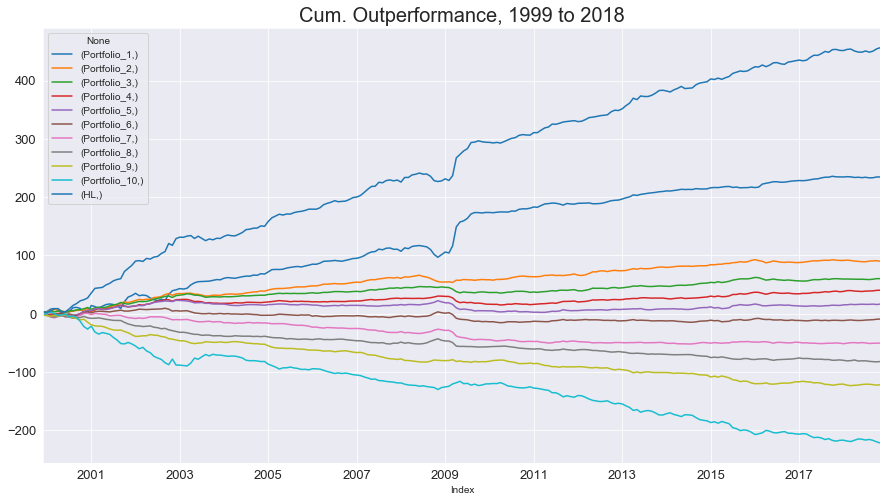

In [17]:
BRT_raw_Eval_Port_cRet[BRT_raw_Eval_Port_cRet.columns].plot.line(
figsize=[15,8],
fontsize=13,                                                              
title ="Cum. Outperformance, %.0f to %.0f" 
% (BRT_raw_Eval_Data.index[0][0].year, BRT_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### Returns vs Predictions

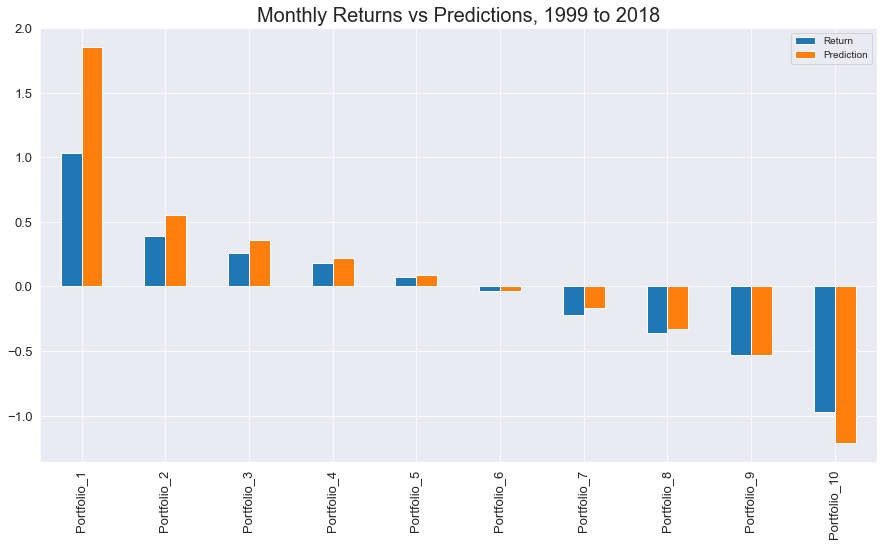

In [18]:
BRT_raw_Eval_Port.loc[:,["Return","Prediction"]].iloc[:-1].plot.bar(
figsize=[15,8],
fontsize=13,
title ="Monthly Returns vs Predictions, %.0f to %.0f" 
% (BRT_raw_Eval_Data.index[0][0].year, BRT_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### Standard deviations

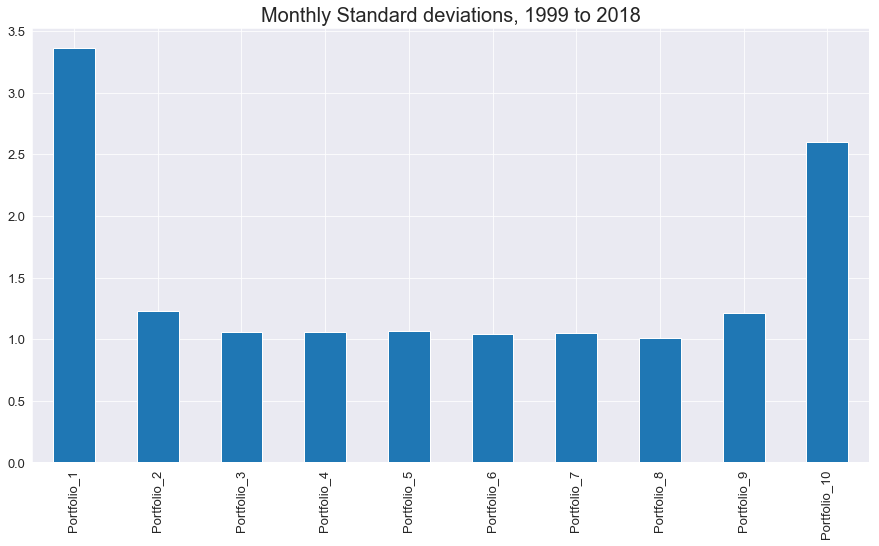

In [19]:
BRT_raw_Eval_Port.loc[:,"Std"].iloc[:-1].plot.bar(
figsize=[15,8], 
fontsize=13,
title ="Monthly Standard deviations, %.0f to %.0f" 
% (BRT_raw_Eval_Data.index[0][0].year, BRT_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### Information Ratios

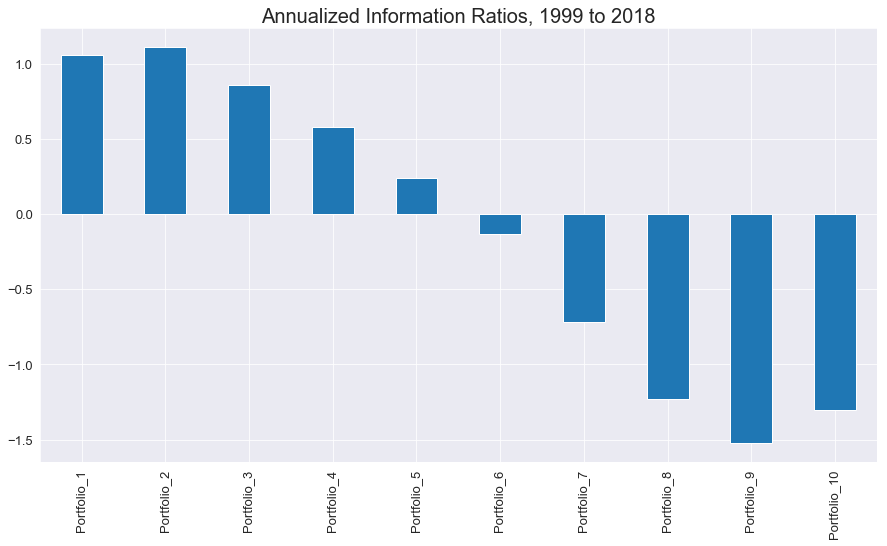

In [20]:
BRT_raw_Eval_Port.loc[:,"IR"].iloc[:-1].plot.bar(
figsize=[15,8],
fontsize=13,
title ="Annualized Information Ratios, %.0f to %.0f" 
% (BRT_raw_Eval_Data.index[0][0].year, BRT_raw_Eval_Data.index[-1][0].year)).title.set_size(20);

### 5.6 Store Model

In [21]:
# Store dataframes 
BRT_raw_Eval_Port.to_pickle("BRT_raw_Eval_Port")
BRT_raw_Eval_Reg.to_pickle("BRT_raw_Eval_Reg")
BRT_raw_Eval_Port_cRet.to_pickle("BRT_raw_Eval_Port_cRet")

### 6 Comparison

In [27]:
# Compare models
compare(Models = ["RF_raw", "BRT_raw"], Globals=globals(), Plot=False).plot.bar(
figsize=[15,8],
fontsize=13,
title ="Comparison of linear models, %.0f to %.0f" 
% ((Data.index[0][0] + pd.offsets.BMonthEnd(Years*12)).year, Data.index[-1][0].year)).title.set_size(20);

KeyError: 'RF_raw_Eval_Reg'